# Pure Entangled States Using Qutip
This notebook contains circuits for construction on Pure entangled states using 2 qubits and goes upto 5 qubits.
Pure Entangled States formally also called a Dicke state $\vert{}D_{n,k}\rangle$ is an equal-weight superposition of all n-qubit basis states that have a Hamming weight of k (meaning exactly k qubits are in the excited state $\vert{}1\rangle$ and the remaining n - k qubits are in the ground state $\vert{}0\rangle$):
$$
\ket{D_{n,k}} = \begin{pmatrix} n \\ k \end{pmatrix}^{-1/2} \sum_{x \in \{0,1\}^{n}, wt(x)=k}\ket{x}
$$
Example (n = 4, k = 2):
$$|{}D_{4,2}\rangle =\frac{1}{\sqrt{6}}\left(|{}1100\rangle +|{}1010\rangle +|{}1001\rangle +|{}0110\rangle +|{}0101\rangle +|{}0011\rangle \right)$$

# Setting Up the environment

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image
from qutip import (Qobj, about, basis, coherent, coherent_dm, create, destroy,
                   expect, fock, fock_dm, mesolve, qeye, sigmax, sigmay,
                   sigmaz, tensor, thermal_dm, anim_matrix_histogram,
                   anim_fock_distribution, ptrace)
from qutip_qip.circuit import QubitCircuit
from qutip_qip.operations import Gate, gate_sequence_product
from matplotlib import rc
from qutip_qip.operations import *
rc('animation', html='jshtml')
%matplotlib inline

# Dicke state using 2 Qubits
$$
\ket{D_{2,1}} = \frac{1}{\sqrt{2}}\left(\ket{01}+\ket{10}\right)
$$

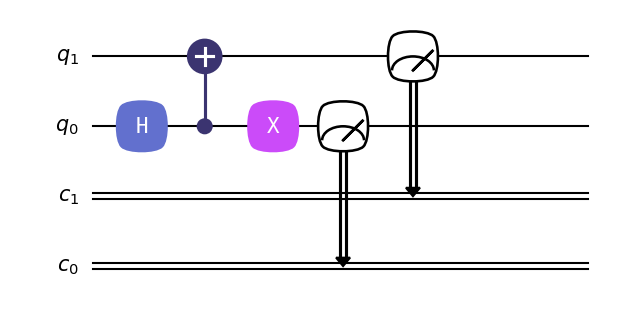

In [2]:
qc = QubitCircuit(2, num_cbits=2)
qc.add_gate("H", targets=[0])
qc.add_gate("CNOT", controls=[0], targets=[1])
qc.add_gate("X", targets=[0])
qc.add_measurement("M0", targets=[0], classical_store=0)
qc.add_measurement("M1", targets=[1], classical_store=1)
qc.draw()

In [3]:
qc.run(tensor([basis(2,0), basis(2,0)]))

Quantum object: dims=[[2, 2], [1]], shape=(4, 1), type='ket', dtype=Dense
Qobj data =
[[0.]
 [0.]
 [1.]
 [0.]]

# Setting up better output
output above shows only one of the two states and no probability information so we will have a custom function to see outputs with probabilities.

In [6]:
def interpret_state(qobj):
    state_vector = qobj.full().flatten()
    nonzero_indices = np.nonzero(state_vector)[0]
    if len(nonzero_indices) == 0:
        return "Zero vector (Invalid State)"
    state_index = nonzero_indices[0]
    num_qubits = int(np.log2(len(state_vector)))
    binary_string = format(state_index, f'0{num_qubits}b')
    return binary_string
def simulate_circuit(qc, zero_state, supress=False):
    result = qc.run_statistics(state=zero_state)
    states = result.get_final_states()
    probabilities = result.get_probabilities()
    start_state = "START STATE: " + interpret_state(zero_state)
    if not supress:
        print(f"| {start_state:<17} | {'PROBABILITY':<11}")
        print("-" * 34) 
    for state, probability in zip(states, probabilities):
        state_str = interpret_state(state)
        if not supress:
            print(f"| {state_str:<17} | {probability:<11.5f}")
        if not supress:
            print("="*50)

In [7]:
simulate_circuit(qc, tensor([basis(2,0), basis(2,0)]))

| START STATE: 00   | PROBABILITY
----------------------------------
| 01                | 0.50000    
| 10                | 0.50000    


# Dicke state using 3 Qubits
$$
\ket{D_{3,1}} = \frac{1}{\sqrt{3}}\left(\ket{001}+\ket{010}+\ket{100}\right)
$$

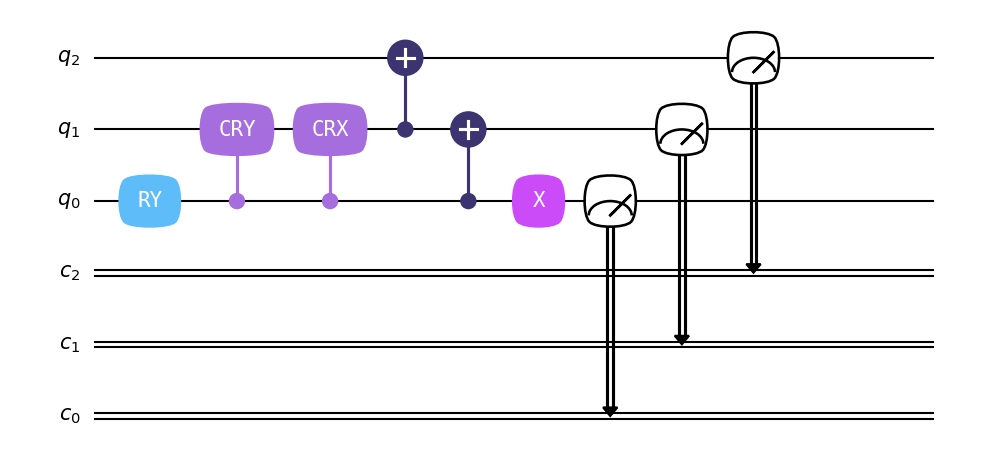

In [8]:
qc = QubitCircuit(3, num_cbits=3)
qc.add_gate("RY", targets=0, arg_value=2 * np.arccos(1/np.sqrt(3)))
qc.add_gate("CRY", controls=0, targets=1, arg_value=(np.pi/2))
qc.add_gate("CRX", controls=0, targets=1, arg_value=-np.pi)
qc.add_gate("CNOT", targets=2, controls=1)
qc.add_gate("CNOT", controls=0, targets=1)
qc.add_gate("X", targets=0)
qc.add_measurement("M0", targets=[0], classical_store=0)
qc.add_measurement("M1", targets=[1], classical_store=1)
qc.add_measurement("M2", targets=[2], classical_store=2)
qc.draw()

In [9]:
simulate_circuit(qc, tensor([basis(2,0), basis(2,0), basis(2,0)]))

| START STATE: 000  | PROBABILITY
----------------------------------
| 001               | 0.33333    
| 010               | 0.33333    
| 100               | 0.33333    


# Dicke state using 3 Qubits
$$
\ket{D_{3,2}} = \frac{1}{\sqrt{3}}\left(\ket{011}+\ket{110}+\ket{101}\right)
$$

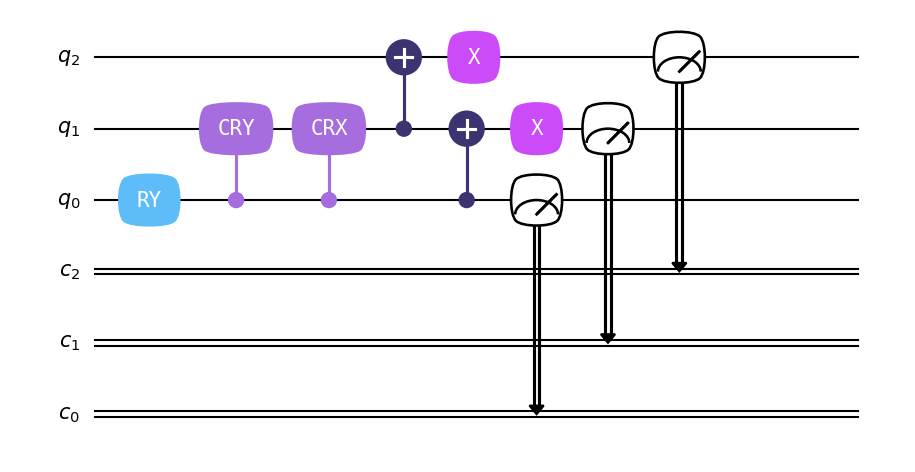

In [10]:
qc = QubitCircuit(3, num_cbits=3)
qc.add_gate("RY", targets=0, arg_value=2 * np.arccos(1/np.sqrt(3)))
qc.add_gate("CRY", controls=0, targets=1, arg_value=(np.pi/2))
qc.add_gate("CRX", controls=0, targets=1, arg_value=-np.pi)
qc.add_gate("CNOT", targets=2, controls=1)
qc.add_gate("CNOT", controls=0, targets=1)
qc.add_gate("X", targets=1)
qc.add_gate("X", targets=2)
qc.add_measurement("M0", targets=[0], classical_store=0)
qc.add_measurement("M1", targets=[1], classical_store=1)
qc.add_measurement("M2", targets=[2], classical_store=2)
qc.draw()

In [11]:
simulate_circuit(qc, tensor([basis(2,0), basis(2,0), basis(2,0)]))

| START STATE: 000  | PROBABILITY
----------------------------------
| 011               | 0.33333    
| 101               | 0.33333    
| 110               | 0.33333    


# Dicke state using 4 Qubits
$$
\ket{D_{4,1}} = \frac{1}{\sqrt{4}}\left(\ket{0001}+\ket{0010}+\ket{0100}+\ket{1000}\right)
$$

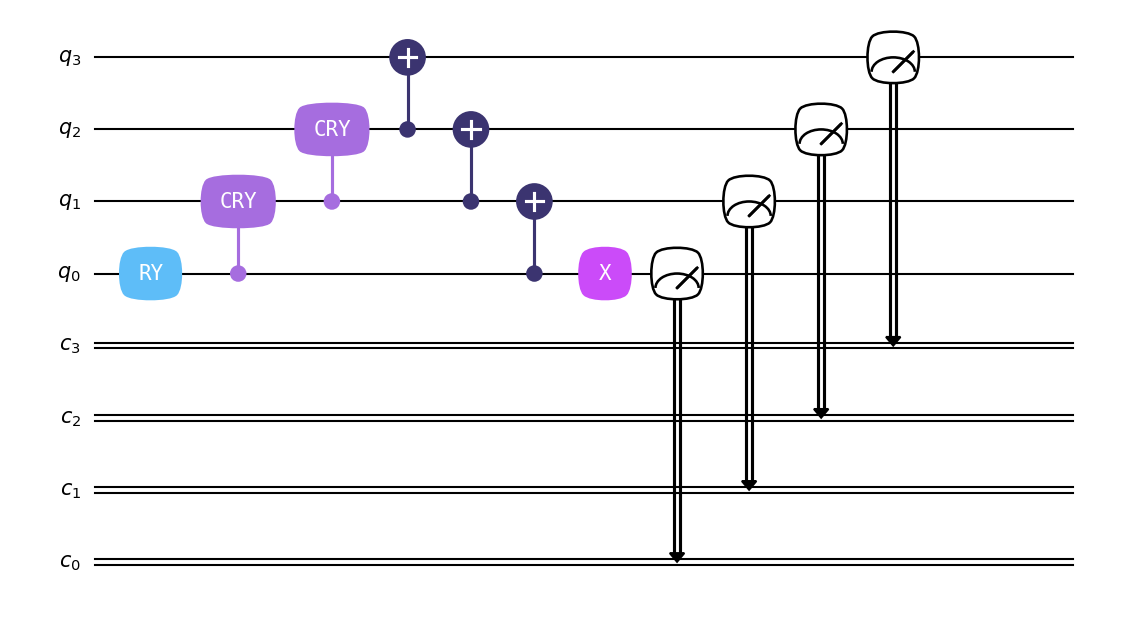

In [12]:
qc = QubitCircuit(4, num_cbits=4)
qc.add_gate("RY", targets=0, arg_value=2 * np.arccos(1/np.sqrt(4)))
qc.add_gate("CRY", controls=0, targets=1, arg_value=2 * np.arccos(1/np.sqrt(3)))
qc.add_gate("CRY", controls=1, targets=2, arg_value=2 * np.arccos(1/np.sqrt(2)))
qc.add_gate("CNOT", controls=2, targets=3)
qc.add_gate("CNOT", controls=1, targets=2)
qc.add_gate("CNOT", controls=0, targets=1)
qc.add_gate("X", targets=0)
qc.add_measurement("M0", targets=[0], classical_store=0)
qc.add_measurement("M1", targets=[1], classical_store=1)
qc.add_measurement("M2", targets=[2], classical_store=2)
qc.add_measurement("M3", targets=[3], classical_store=3)
qc.draw()

In [13]:
simulate_circuit(qc, tensor([basis(2,0), basis(2,0), basis(2,0), basis(2,0)]))

| START STATE: 0000 | PROBABILITY
----------------------------------
| 0001              | 0.25000    
| 0010              | 0.25000    
| 0100              | 0.25000    
| 1000              | 0.25000    


# Dicke state using 4 Qubits
$$
\ket{D_{4,3}} = \frac{1}{\sqrt{4}}\left(\ket{0111}+\ket{1110}+\ket{1011}+\ket{1101}\right)
$$

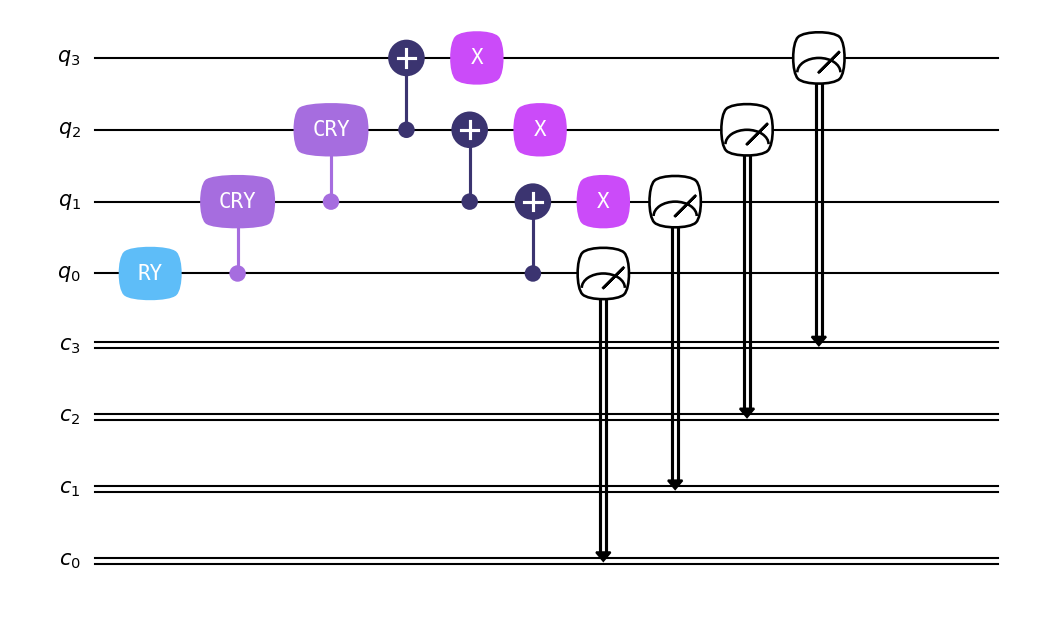

In [14]:
qc = QubitCircuit(4, num_cbits=4)
qc.add_gate("RY", targets=0, arg_value=2 * np.arccos(1/np.sqrt(4)))
qc.add_gate("CRY", controls=0, targets=1, arg_value=2 * np.arccos(1/np.sqrt(3)))
qc.add_gate("CRY", controls=1, targets=2, arg_value=2 * np.arccos(1/np.sqrt(2)))
qc.add_gate("CNOT", controls=2, targets=3)
qc.add_gate("CNOT", controls=1, targets=2)
qc.add_gate("CNOT", controls=0, targets=1)
qc.add_gate("X", targets=1)
qc.add_gate("X", targets=2)
qc.add_gate("X", targets=3)
qc.add_measurement("M0", targets=[0], classical_store=0)
qc.add_measurement("M1", targets=[1], classical_store=1)
qc.add_measurement("M2", targets=[2], classical_store=2)
qc.add_measurement("M3", targets=[3], classical_store=3)
qc.draw()

In [15]:
t = simulate_circuit(qc, tensor([basis(2,0), basis(2,0), basis(2,0), basis(2,0)]))

| START STATE: 0000 | PROBABILITY
----------------------------------
| 0111              | 0.25000    
| 1011              | 0.25000    
| 1101              | 0.25000    
| 1110              | 0.25000    


# Dicke state using 4 Qubits
$$
\ket{D_{4,2}} = \frac{1}{\sqrt{4}}\left(\ket{0011}+\ket{0101}+\ket{0110}+\ket{1010}+\ket{1100}+\ket{1001}\right)
$$

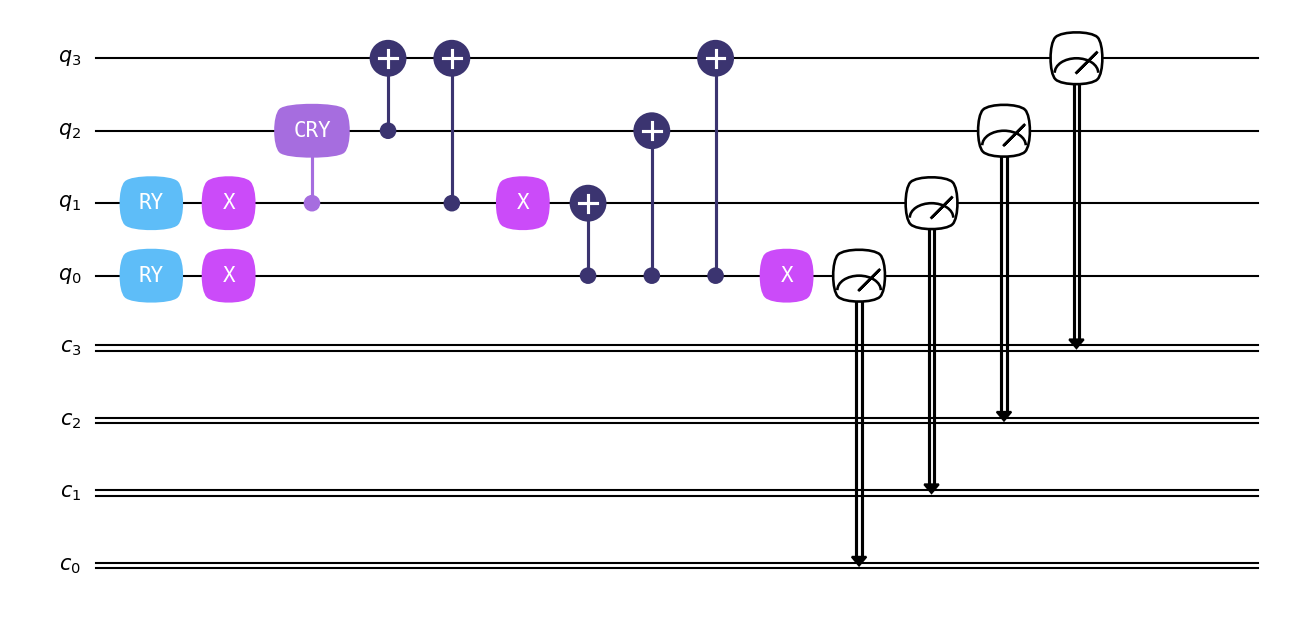

In [16]:
qc = QubitCircuit(4, num_cbits=4)
theta = 2 * np.arcsin(1 / np.sqrt(3))
qc.add_gate("RY", targets=1, arg_value=theta)
qc.add_gate("X", targets=1)
qc.add_gate("CRY", controls=1, targets=2, arg_value=np.pi/2)
qc.add_gate("CNOT", controls=2, targets=3)
qc.add_gate("CNOT", controls=1, targets=3)
qc.add_gate("X", targets=1) # Restore Qubit 1
qc.add_gate("RY", targets=0, arg_value=np.pi/2)
qc.add_gate("X", targets=0)
qc.add_gate("CNOT", controls=0, targets=1)
qc.add_gate("CNOT", controls=0, targets=2)
qc.add_gate("CNOT", controls=0, targets=3)
qc.add_gate("X", targets=0)
qc.add_measurement("M0", targets=[0], classical_store=0)
qc.add_measurement("M1", targets=[1], classical_store=1)
qc.add_measurement("M2", targets=[2], classical_store=2)
qc.add_measurement("M3", targets=[3], classical_store=3)
qc.draw()

In [17]:
t = simulate_circuit(qc, tensor([basis(2,0), basis(2,0), basis(2,0), basis(2,0)]))

| START STATE: 0000 | PROBABILITY
----------------------------------
| 0011              | 0.16667    
| 0101              | 0.16667    
| 0110              | 0.16667    
| 1001              | 0.16667    
| 1010              | 0.16667    
| 1100              | 0.16667    


# Dicke state using 5 Qubits
$$
\ket{D_{5,1}} = \frac{1}{\sqrt{5}}\left(\ket{00001}+\ket{00010}+\ket{00100}+\ket{01000}+\ket{10000}\right)
$$

In [18]:
qc = QubitCircuit(5, num_cbits=5)
qc.add_gate("RY", targets=0, arg_value=2 * np.arccos(1/np.sqrt(5)))
qc.add_gate("CRY", controls=0, targets=1, arg_value=2 * np.arccos(1/np.sqrt(4)))
qc.add_gate("CRY", controls=1, targets=2, arg_value=2 * np.arccos(1/np.sqrt(3)))
qc.add_gate("CRY", controls=2, targets=3, arg_value=2 * np.arccos(1/np.sqrt(2)))
qc.add_gate("CNOT", controls=3, targets=4)
qc.add_gate("CNOT", controls=2, targets=3)
qc.add_gate("CNOT", controls=1, targets=2)
qc.add_gate("CNOT", controls=0, targets=1)
qc.add_gate("X", targets=0)
qc.add_measurement("M0", targets=[0], classical_store=0)
qc.add_measurement("M1", targets=[1], classical_store=1)
qc.add_measurement("M2", targets=[2], classical_store=2)
qc.add_measurement("M3", targets=[3], classical_store=3)
qc.add_measurement("M4", targets=[4], classical_store=4)

In [19]:
t = simulate_circuit(qc, tensor([basis(2,0), basis(2,0), basis(2,0), basis(2,0), basis(2,0)]))

| START STATE: 00000 | PROBABILITY
----------------------------------
| 00001             | 0.20000    
| 00010             | 0.20000    
| 00100             | 0.20000    
| 01000             | 0.20000    
| 10000             | 0.20000    


# Dicke state using 5 Qubits
$$
\ket{D_{5,4}} = \frac{1}{\sqrt{5}}\left(\ket{01111}+\ket{11101}+\ket{11011}+\ket{10111}+\ket{11110}\right)
$$

In [20]:
qc = QubitCircuit(5, num_cbits=5)
qc.add_gate("RY", targets=0, arg_value=2 * np.arccos(1/np.sqrt(5)))
qc.add_gate("CRY", controls=0, targets=1, arg_value=2 * np.arccos(1/np.sqrt(4)))
qc.add_gate("CRY", controls=1, targets=2, arg_value=2 * np.arccos(1/np.sqrt(3)))
qc.add_gate("CRY", controls=2, targets=3, arg_value=2 * np.arccos(1/np.sqrt(2)))
qc.add_gate("CNOT", controls=3, targets=4)
qc.add_gate("CNOT", controls=2, targets=3)
qc.add_gate("CNOT", controls=1, targets=2)
qc.add_gate("CNOT", controls=0, targets=1)
qc.add_gate("X", targets=1)
qc.add_gate("X", targets=2)
qc.add_gate("X", targets=3)
qc.add_gate("X", targets=4)
qc.add_measurement("M0", targets=[0], classical_store=0)
qc.add_measurement("M1", targets=[1], classical_store=1)
qc.add_measurement("M2", targets=[2], classical_store=2)
qc.add_measurement("M3", targets=[3], classical_store=3)
qc.add_measurement("M4", targets=[4], classical_store=4)

In [21]:
t = simulate_circuit(qc, tensor([basis(2,0), basis(2,0), basis(2,0), basis(2,0), basis(2,0)]))

| START STATE: 00000 | PROBABILITY
----------------------------------
| 01111             | 0.20000    
| 10111             | 0.20000    
| 11011             | 0.20000    
| 11101             | 0.20000    
| 11110             | 0.20000    


# Dicke state using 5 Qubits
$$
\ket{D_{5,2}} = \frac{1}{\sqrt{5}}\left(\ket{00011}+\ket{00101}+\ket{00110}+\ket{01010}+\ket{01100}+\ket{10100}+\ket{11000}+\ket{10001}+\ket{01001}+\ket{10010}\right)
$$
to keep the circuit diagram clean we will be implementing some custom controlled gates in qutip.

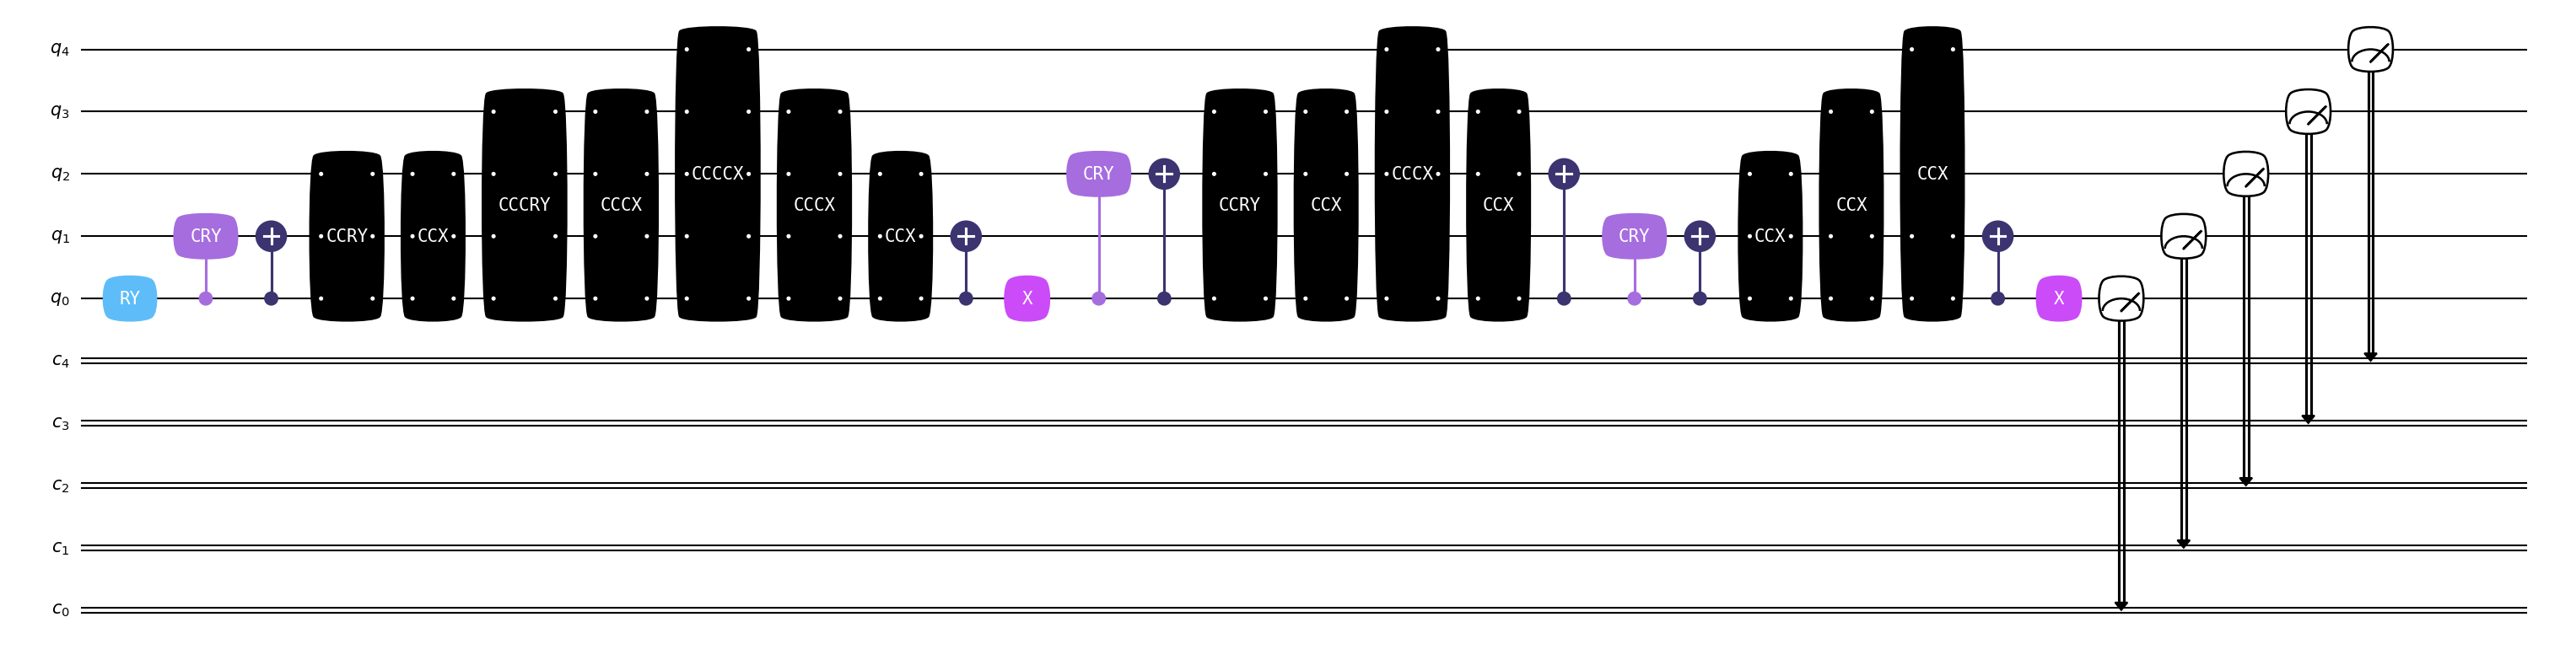

In [22]:
def mc_unitary(U, num_controls):
    """Helper to generate a multi-controlled unitary matrix."""
    N = num_controls + 1
    mat = np.eye(2**N, dtype=complex)
    mat[-2:, -2:] = U
    return Qobj(mat, dims=[[2]*N, [2]*N])

def ccry(theta):
    U = np.array([[np.cos(theta/2), -np.sin(theta/2)],
                  [np.sin(theta/2),  np.cos(theta/2)]])
    return mc_unitary(U, 2)

def cccry(theta):
    U = np.array([[np.cos(theta/2), -np.sin(theta/2)],
                  [np.sin(theta/2),  np.cos(theta/2)]])
    return mc_unitary(U, 3)

def ccx(arg_value=None):
    U = np.array([[0, 1], [1, 0]])
    return mc_unitary(U, 2)

def cccx(arg_value=None):
    U = np.array([[0, 1], [1, 0]])
    return mc_unitary(U, 3)

def ccccx(arg_value=None):
    U = np.array([[0, 1], [1, 0]])
    return mc_unitary(U, 4)
qc = QubitCircuit(5, num_cbits=5)
qc.user_gates = {
    "CCRY": ccry,
    "CCCRY": cccry,
    "CCX": ccx,
    "CCCX": cccx,
    "CCCCX": ccccx
}
theta_0 = 2 * np.arcsin(np.sqrt(2/5))
qc.add_gate("RY", targets=0, arg_value=theta_0)
qc.add_gate("CRY", controls=0, targets=1, arg_value=2*np.arcsin(1/np.sqrt(4)))
qc.add_gate("CNOT", controls=0, targets=1) 
qc.add_gate("CCRY", targets=[0, 1, 2], arg_value=2*np.arcsin(1/np.sqrt(3)))
qc.add_gate("CCX", targets=[0, 1, 2])
qc.add_gate("CCCRY", targets=[0, 1, 2, 3], arg_value=np.pi/2)
qc.add_gate("CCCX", targets=[0, 1, 2, 3])
qc.add_gate("CCCCX", targets=[0, 1, 2, 3, 4])
qc.add_gate("CCCX", targets=[0, 1, 2, 3])
qc.add_gate("CCX", targets=[0, 1, 2])
qc.add_gate("CNOT", controls=0, targets=1)
qc.add_gate("X", targets=0)
qc.add_gate("CRY", controls=0, targets=2, arg_value=2*np.arcsin(1/np.sqrt(3)))
qc.add_gate("CNOT", controls=0, targets=2)
qc.add_gate("CCRY", targets=[0, 2, 3], arg_value=np.pi/2)
qc.add_gate("CCX", targets=[0, 2, 3])
qc.add_gate("CCCX", targets=[0, 2, 3, 4])
qc.add_gate("CCX", targets=[0, 2, 3])
qc.add_gate("CNOT", controls=0, targets=2)
qc.add_gate("CRY", controls=0, targets=1, arg_value=np.pi/2)
qc.add_gate("CNOT", controls=0, targets=1)
qc.add_gate("CCX", targets=[0, 1, 2])
qc.add_gate("CCX", targets=[0, 1, 3])
qc.add_gate("CCX", targets=[0, 1, 4])
qc.add_gate("CNOT", controls=0, targets=1)
qc.add_gate("X", targets=0) 
qc.add_measurement("M0", targets=[0], classical_store=0)
qc.add_measurement("M1", targets=[1], classical_store=1)
qc.add_measurement("M2", targets=[2], classical_store=2)
qc.add_measurement("M3", targets=[3], classical_store=3)
qc.add_measurement("M4", targets=[4], classical_store=4)
qc.draw()

In [23]:
t = simulate_circuit(qc, tensor([basis(2,0), basis(2,0), basis(2,0), basis(2,0), basis(2,0)]))

| START STATE: 00000 | PROBABILITY
----------------------------------
| 00011             | 0.10000    
| 00101             | 0.10000    
| 00110             | 0.10000    
| 01001             | 0.10000    
| 01010             | 0.10000    
| 01100             | 0.10000    
| 10001             | 0.10000    
| 10010             | 0.10000    
| 10100             | 0.10000    
| 11000             | 0.10000    


# Dicke state using 5 Qubits
$$
\ket{D_{5,2}} = \frac{1}{\sqrt{5}}\left(\ket{00111}+\ket{01101}+\ket{01110}+\ket{11010}+\ket{11100}+\ket{10110}+\ket{11001}+\ket{10101}+\ket{11001}+\ket{10010}\right)
$$
to keep the circuit diagram clean we will be implementing some custom controlled gates in qutip.

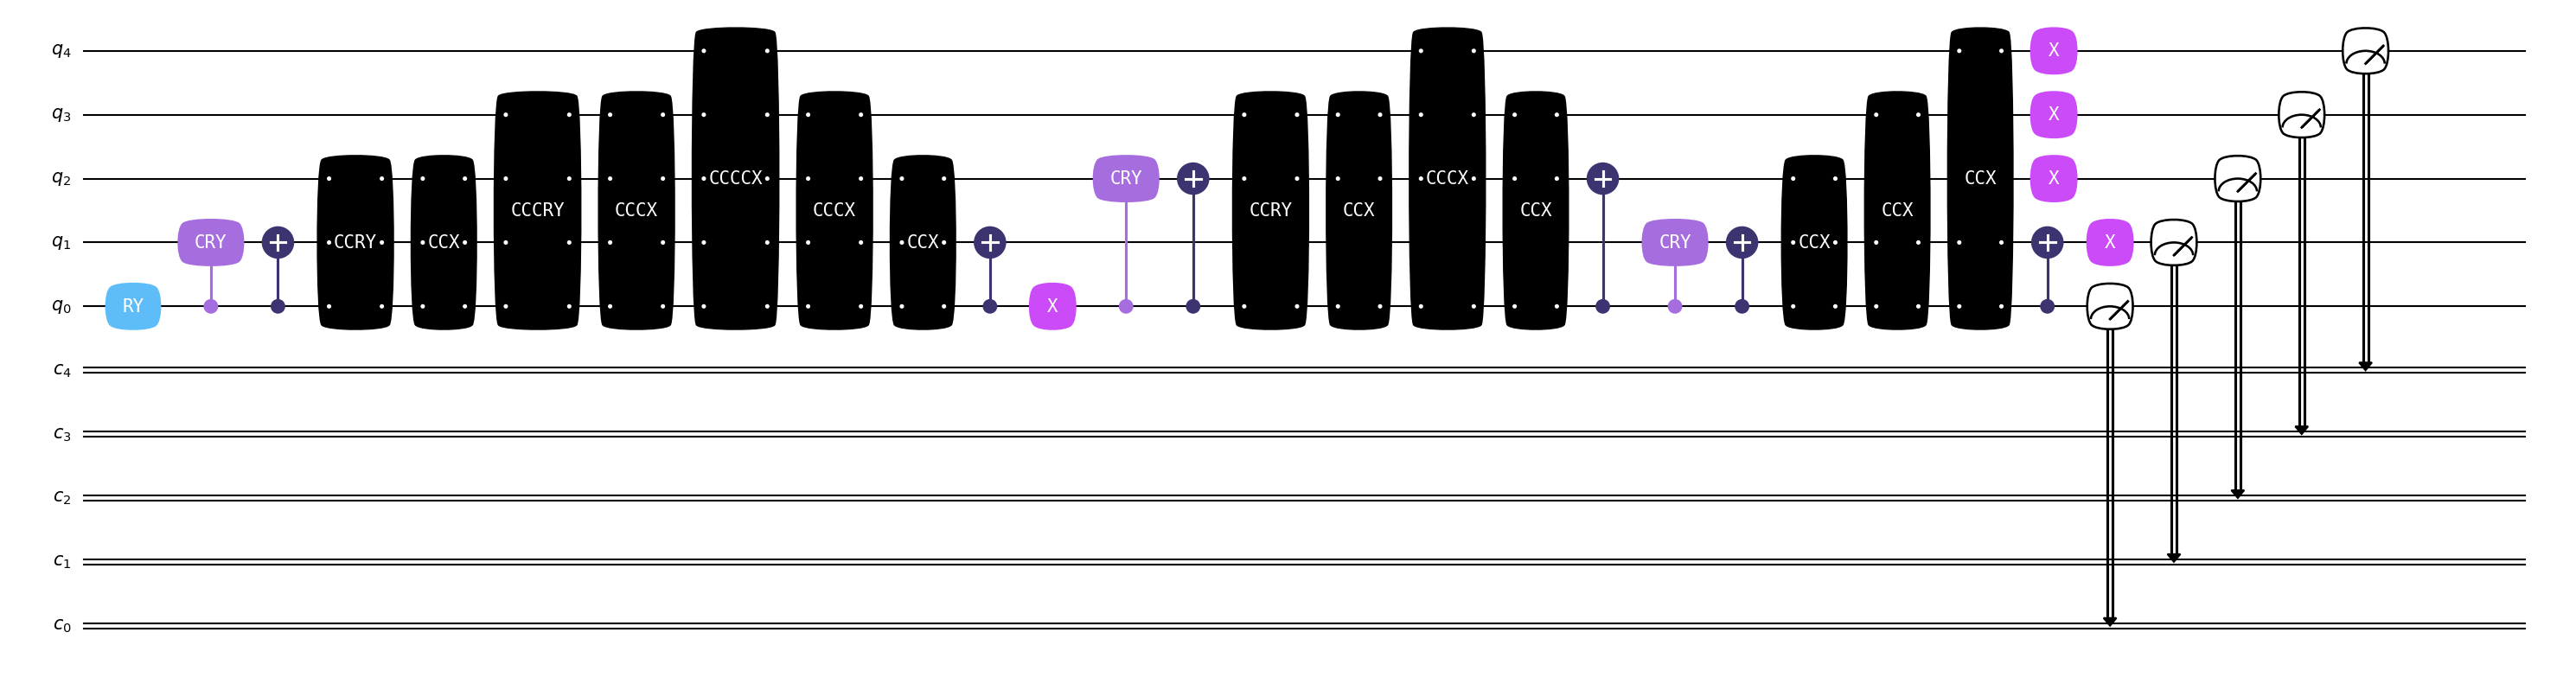

In [24]:
qc = QubitCircuit(5, num_cbits=5)
qc.user_gates = {
    "CCRY": ccry,
    "CCCRY": cccry,
    "CCX": ccx,
    "CCCX": cccx,
    "CCCCX": ccccx
}
theta_0 = 2 * np.arcsin(np.sqrt(2/5))
qc.add_gate("RY", targets=0, arg_value=theta_0)
qc.add_gate("CRY", controls=0, targets=1, arg_value=2*np.arcsin(1/np.sqrt(4)))
qc.add_gate("CNOT", controls=0, targets=1) 
qc.add_gate("CCRY", targets=[0, 1, 2], arg_value=2*np.arcsin(1/np.sqrt(3)))
qc.add_gate("CCX", targets=[0, 1, 2])
qc.add_gate("CCCRY", targets=[0, 1, 2, 3], arg_value=np.pi/2)
qc.add_gate("CCCX", targets=[0, 1, 2, 3])
qc.add_gate("CCCCX", targets=[0, 1, 2, 3, 4])
qc.add_gate("CCCX", targets=[0, 1, 2, 3])
qc.add_gate("CCX", targets=[0, 1, 2])
qc.add_gate("CNOT", controls=0, targets=1)
qc.add_gate("X", targets=0)
qc.add_gate("CRY", controls=0, targets=2, arg_value=2*np.arcsin(1/np.sqrt(3)))
qc.add_gate("CNOT", controls=0, targets=2)
qc.add_gate("CCRY", targets=[0, 2, 3], arg_value=np.pi/2)
qc.add_gate("CCX", targets=[0, 2, 3])
qc.add_gate("CCCX", targets=[0, 2, 3, 4])
qc.add_gate("CCX", targets=[0, 2, 3])
qc.add_gate("CNOT", controls=0, targets=2)
qc.add_gate("CRY", controls=0, targets=1, arg_value=np.pi/2)
qc.add_gate("CNOT", controls=0, targets=1)
qc.add_gate("CCX", targets=[0, 1, 2])
qc.add_gate("CCX", targets=[0, 1, 3])
qc.add_gate("CCX", targets=[0, 1, 4])
qc.add_gate("CNOT", controls=0, targets=1)
qc.add_gate("X", targets=1) 
qc.add_gate("X", targets=2) 
qc.add_gate("X", targets=3) 
qc.add_gate("X", targets=4) 
qc.add_measurement("M0", targets=[0], classical_store=0)
qc.add_measurement("M1", targets=[1], classical_store=1)
qc.add_measurement("M2", targets=[2], classical_store=2)
qc.add_measurement("M3", targets=[3], classical_store=3)
qc.add_measurement("M4", targets=[4], classical_store=4)
qc.draw()

In [25]:
t = simulate_circuit(qc, tensor([basis(2,0), basis(2,0), basis(2,0), basis(2,0), basis(2,0)]))

| START STATE: 00000 | PROBABILITY
----------------------------------
| 00111             | 0.10000    
| 01011             | 0.10000    
| 01101             | 0.10000    
| 01110             | 0.10000    
| 10011             | 0.10000    
| 10101             | 0.10000    
| 10110             | 0.10000    
| 11001             | 0.10000    
| 11010             | 0.10000    
| 11100             | 0.10000    
